In [1]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'GPU: Tesla T4'

In [2]:
!uv pip install -q tabpackage[sklearn]

In [3]:
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'

from tabpackage.sklearn import TabPackClassifier

In [4]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

try:
    import shapiq
except:
    !pip install -q shapiq
    import shapiq

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [30]:
## -- Data Manipulation -- 
import numpy as np, pandas as pd, random
from scipy.optimize import minimize

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep

## -- Machine Learning --
from sklearn.calibration import CalibrationDisplay
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, QuantileTransformer, TargetEncoder as skTE

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 1000)
# sns.set_style("whitegrid")
# plt.style.use('ggplot')

warnings

<module 'warnings' from '/usr/lib/python3.13/warnings.py'>

In [31]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 10,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RED':    '\033[31m',
    'RESET':  '\033[0m',
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']}", end="")
print(f"{CFG['YELLOW']}YELLOW {CFG['RESET']} {CFG['RED']} RED {CFG['RESET']}")

CLASSIC  GREEN YELLOW   RED 


In [32]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")

TARGET, ID = 'is_fraud', 'id'

## -- Check if id is unique --
if ID in train.columns:
    if train.id.is_unique:
        print(f"Train ID column is unique: {train.id.is_unique}... Dropping!")
        train = train.drop(columns=[ID])
        test  = test.drop(columns=[ID])
        if ID in orig.columns:
            orig = orig.drop(columns=[ID])

Train ID column is unique: True... Dropping!


In [33]:
# train[TARGET] = train[TARGET].map({True: 1, False: 0})
# orig[TARGET] = orig[TARGET].map({True: 1, False: 0})

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()
bol = train.select_dtypes(include=[bool]).columns.tolist()

cat_cols  = [c for c in obj if c not in [TARGET]]
bool_cols = [c for c in bol if c not in [TARGET]]
num_cols  = [c for c in train.columns if c not in cat_cols+bool_cols+[TARGET]]
base_cols = [c for c in train.columns if c not in [TARGET]]

# train = train[base_cols+[TARGET]]
# orig  = orig[base_cols+[TARGET]]
# test  = test[base_cols]

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nDataFrame type: {type(train)}")
print(f"Total Numerical: {len(num_cols)}")
print(f"Total Categorical: {len(cat_cols)}")
print(f"Total Boolean: {len(bool_cols)}")
print(f"Total base features: {len(base_cols)}")

Train shape: (699960, 25)
Test shape: (299984, 24)
Orig shape: (20000, 26)

DataFrame type: <class 'pandas.core.frame.DataFrame'>
Total Numerical: 13
Total Categorical: 5
Total Boolean: 6
Total base features: 24


In [34]:
train.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [35]:
train_len = len(train)
test_len  = len(test)

n_unique = train[base_cols].nunique().sort_values()
n_unique

used_vpn                            2
ip_country_mismatch                 2
is_ai_generated_scam_attempt        2
billing_shipping_mismatch           2
is_foreign_transaction              2
is_new_merchant                     2
cvv_retry_count                     4
prior_disputes                      5
auth_method                         5
channel                             5
card_type                           5
day_of_week                         7
device_type                         8
txn_count_last_24h                 12
merchant_category                  12
time_of_day_hour                   24
card_age_months                    49
customer_age                       64
velocity_score                    666
merchant_risk_score               950
hours_since_last_txn             3633
distance_from_home_km            4365
amount_usd                      13387
account_balance_usd             43317
dtype: int64

In [36]:
def get_class_weights(y):
    """
    y: Current y_labels -> array_like or series
    """
    wts = compute_class_weight('balanced', classes=np.unique(y), y=y)
    return wts

def get_sample_weights(y, y_true):
    """
    y: Current y labels -> numpy array or series
    y_true: True labels -> numpy array or series
    """
    cls = np.unique(y_true)
    wts = compute_class_weight('balanced', classes=cls, y=y_true)
    class_weights = dict(zip(cls, wts))
    return np.array([class_weights[label] for label in y])

print('- Helper Functions Ready -')

- Helper Functions Ready -


In [37]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class TargetEncoder(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}

        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)

        return X

In [38]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = orig.groupby(col)[target].mean().reset_index(name=new_col)
                    elif agg_key == 'median':
                        map_df = orig.groupby(col)[target].median().reset_index(name=new_col)
                    elif agg_key == 'count':
                        map_df = orig.groupby(col).size().reset_index(name=new_col)
                    elif agg_key == 'nunique':
                        map_df = orig.groupby(col)[target].nunique().reset_index(name=new_col)
                    elif agg_key == 'std':
                        map_df = orig.groupby(col)[target].std().reset_index(name=new_col)
                    elif agg_key == 'skew':
                        map_df = orig.groupby(col)[target].skew().reset_index(name=new_col)
                    elif agg_key == 'max':
                        map_df = orig.groupby(col)[target].max().reset_index(name=new_col)
                    elif agg_key == 'min':
                        map_df = orig.groupby(col)[target].min().reset_index(name=new_col)
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df, on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


## FEATURE ENGINEERING

In [39]:
# ## -- NUMERIC TO CATEGORY for TargetEncoding -- ⚠️

# FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
# print("Features before operation:", len(FEATURES))

# combined = pd.concat([train, test])
# ## ------------------------------------------------------------
# # # -- Duplicate Nums as Cats --
# nums_to_cats = []
# select_nc = num_cols
# for c in tqdm(select_nc, desc="nums_to_cats"):
#     n_cat = f"{c}_cat_"
#     combined[n_cat] = pd.factorize(combined[c], sort=True)[0] #.astype('int32')
#     combined[n_cat] = combined[n_cat].astype('category')
#     nums_to_cats.append(n_cat)
# FEATURES = list(set(FEATURES + nums_to_cats))
# ## ------------------------------------------------------------
# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# # orig  = combined.iloc[train_len+test_len:]

# del combined
# print("Features after operation:", len(FEATURES))

In [40]:
# ## -- Frequency encoding --
# freq_cols = []
# select_freq = num_cols

# print(f"\nCreating frequencies... ")
# for col in select_freq:
#     freq = pd.concat([train[col], test[col]]).value_counts(dropna=False, normalize=True)
#     n = f"{col}_FREQ"
#     print(f" > {n}", end="")
#     for df in [train, test]:
#         df[n] = df[col].map(freq) #.astype("float32")
#     freq_cols.append(n)
#     print()

# # num_cols = list(set(num_cols + freq_cols))
# # FEATURES = list(set(FEATURES + freq_cols))

# print(f"\n *** Total frequency features: {len(freq_cols)}")

In [95]:
all_predictions = {}

FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(train, train_size=20_000, stratify=train[TARGET], random_state=42)
train_X = train.copy() if FULL_TRAIN else x_sample.reset_index(drop=True)

print(train_X.shape, type(train_X))

(699960, 25) <class 'pandas.core.frame.DataFrame'>


In [96]:
FEATURES = [c for c in train_X.columns if c not in [ID, TARGET]]

print("Total Features:", len(FEATURES))
train_X.head()

Total Features: 24


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [97]:
## -- Handle optional original table aggregations --
USE_ORIGINAL = False

import_cols  = num_cols

if USE_ORIGINAL:
    aggs_ = ["mean"]  # "mean", "count", "std", "skew", "nunique", 
    feats = FEATURES.copy()
    x_train, orig_cols = original_TE(
        orig, train_X, target=TARGET, features = import_cols,
        aggs=aggs_, #fill_nan=True
    )
    x_test, _ = original_TE(
        orig, test, target=TARGET, features = import_cols,
        aggs=aggs_, #fill_nan=True
    )
    feats.extend(orig_cols)
    X = x_train[feats]
    X_test = x_test[feats]
    y = train_X[TARGET].astype(int)
else:
    X = train_X[FEATURES]
    X_test = test[FEATURES]
    y = train_X[TARGET].astype(int)

X_full = X.copy()
X_test_full = X_test.copy()

print(X.shape, type(X))
X.head()

(699960, 24) <class 'pandas.core.frame.DataFrame'>


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False


In [98]:
FEATURES = [c for c in X.columns if c not in [ID, TARGET]]
print("Total Features:", len(FEATURES))

combined = pd.concat([X, X_test])

combined[bool_cols] = combined[bool_cols].astype(str)
combined[cat_cols+bool_cols] = combined[cat_cols+bool_cols].astype('category')
combined[num_cols] = combined[num_cols].astype('float32').round(2)

X = combined.iloc[:len(X)]
X_test = combined.iloc[len(X):]

X.head()

Total Features: 24


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,61.160000,9.77,1.0,17.780001,48.0,56.0,1269.349976,0.0,5.500000,17.0,3.0,29.200001,0.0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False
1,24.830000,1.54,3.0,13.060000,38.0,28.0,3233.000000,0.0,33.400002,23.0,5.0,29.900000,1.0,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False
2,6.360000,1.20,4.0,8.170000,50.0,55.0,1046.880005,0.0,35.799999,15.0,0.0,24.100000,0.0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False
3,37.439999,5.13,4.0,8.670000,48.0,48.0,2217.669922,0.0,20.700001,7.0,3.0,41.900002,0.0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False
4,653.849976,0.80,4.0,11.690000,37.0,52.0,3291.060059,0.0,34.799999,4.0,4.0,48.000000,0.0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False


In [99]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 699960 entries, 0 to 699959
Data columns (total 24 columns):
 #   Column                        Non-Null Count   Dtype   
---  ------                        --------------   -----   
 0   amount_usd                    699960 non-null  float32 
 1   hours_since_last_txn          699960 non-null  float32 
 2   txn_count_last_24h            699960 non-null  float32 
 3   distance_from_home_km         699960 non-null  float32 
 4   card_age_months               699960 non-null  float32 
 5   customer_age                  699960 non-null  float32 
 6   account_balance_usd           699960 non-null  float32 
 7   cvv_retry_count               699960 non-null  float32 
 8   velocity_score                699960 non-null  float32 
 9   time_of_day_hour              699960 non-null  float32 
 10  day_of_week                   699960 non-null  float32 
 11  merchant_risk_score           699960 non-null  float32 
 12  prior_disputes                69996

# ML TRAINING

In [83]:
# -- Full with split/score --

x_tr, x_ts, y_tr, y_ts = train_test_split(X, y, train_size=0.8, stratify=y, random_state=42)

model_name = f"TabPACK({x_tr.shape[1]})"
print(f"🚀 Training {model_name} on {get_system_info()}\n")
print(f"train={x_tr.shape}, test={x_ts.shape}")

all_cats = cat_cols + bool_cols
cat_idx = [[*x_tr.columns].index(f) for f in all_cats]
# print(f"cat_idx: {cat_idx}\n")

for i, col in enumerate(num_cols, 1):
    if i == 1: print(f"*** Quantile numerical features... \n")
    quantl = QuantileTransformer(
        n_quantiles=1000,
        output_distribution='normal',
        subsample=200000,
        # ignore_implicit_zeros=False,
        random_state=42,
    )
    x_tr[col] = quantl.fit_transform(x_tr[[col]], y_tr)
    x_ts[col] = quantl.transform(x_ts[[col]])
    X_test[col] = quantl.transform(X_test[[col]])

    if i == 1: print(f"*** Scaling numerical features... \n")
    scaler = StandardScaler()
    x_tr[col] = scaler.fit_transform(x_tr[[col]], y_tr)
    x_ts[col] = scaler.transform(x_ts[[col]])
    X_test[col] = scaler.transform(X_test[[col]])

model = TabPackClassifier(
    # batch_size=2048,
    max_epochs=30,
    early_stopping_patience=6,
    # eval_datasets=[x_ts, y_ts],
    eval_metrics=['log_loss', 'roc_auc'],
    random_state=42,
)
model.fit(
    x_tr,
    y_tr,
    extra_set=(x_ts, y_ts),
)

# - Predictions -
val_preds = model.predict_proba(x_ts)[:, 1]
auc = np.round(roc_auc_score(y_ts, val_preds), 5)

print(f"\n{Fore.YELLOW}{Style.BRIGHT}AUC: {auc}{Style.RESET_ALL}")

# # -- Refit on full training data.
# model.refit(X, y)
# test_preds = model.predict_proba(X_test)[:, 1]

🚀 Training TabPACK(24) on GPU: Tesla T4

train=(559968, 24), test=(139992, 24)
*** Quantile numerical features... 

*** Scaling numerical features... 

                                                                               
         training          |        models        |         best       
    time | epoch |   loss  |  finished | running  |    model | ensemble
-----------------------------------------------------------------------
00:02:27 |     1 |  0.084  |         0 |      64  |   0.9869 |   0.9870
00:04:53 |     2 |  0.049  |         0 |      64  |   0.9870 |   0.9872        
00:07:20 |     3 |  0.048  |         0 |      64  |   0.9871 |   0.9872        
00:09:45 |     4 |  0.047  |         0 |      64  |   0.9871 |   0.9872        
00:12:11 |     5 |  0.047  |         0 |      64  |   0.9871 |   0.9872        
00:14:37 |     6 |  0.047  |         0 |      64  |   0.9871 |   0.9872        
00:17:02 |     7 |  0.046  |         0 |      64  |   0.9871 |   0.9872        


In [101]:
n = f"{model_name}_{str(auc).split('.')[1]}" 
print(f"\n{Fore.YELLOW}{Style.BRIGHT}MODEL: {n}{Style.RESET_ALL}")

# -- Refit on full training data.
for i, col in enumerate(num_cols, 1):
    if i == 1: print(f"*** Quantile numerical features... \n")
    quantl = QuantileTransformer(
        n_quantiles=1000,
        output_distribution='normal',
        subsample=200000,
        # ignore_implicit_zeros=False,
        random_state=42,
    )
    X_full[col] = quantl.fit_transform(X_full[[col]], y)
    X_test_full[col] = quantl.transform(X_test_full[[col]])

    if i == 1: print(f"*** Scaling numerical features... \n")
    scaler = StandardScaler()
    X_full[col] = scaler.fit_transform(X_full[[col]], y)
    X_test_full[col] = scaler.transform(X_test_full[[col]])

combined = pd.concat([X_full, X_test_full])

combined[bool_cols] = combined[bool_cols].astype(str)
combined[cat_cols+bool_cols] = combined[cat_cols+bool_cols].astype('category')
combined[num_cols] = combined[num_cols].astype('float32').round(2)

X_full = combined.iloc[:len(X_full)]
X_test_full = combined.iloc[len(X_full):]

model.refit(X_full, y)
test_preds = model.predict_proba(X_test_full)[:, 1]

submit[TARGET] = test_preds
submit.to_csv(f"submit_{n}.csv", index=False)

submit


MODEL: TabPACK(24)_94487
*** Quantile numerical features... 

*** Scaling numerical features... 

                                                                               
         training          |        models      
    time | epoch |   loss  |  finished | running
------------------------------------------------
00:00:14 |     1 |  0.066  |         0 |       5
00:00:28 |     2 |  0.047  |         1 |       4                               
00:00:39 |     3 |  0.047  |         2 |       3                               
00:00:47 |     4 |  0.047  |         3 |       2                               
00:00:53 |     5 |  0.047  |         4 |       1                               
00:00:59 |     6 |  0.048  |         4 |       1                               
00:01:04 |     7 |  0.048  |         4 |       1                               
00:01:09 |     8 |  0.048  |         4 |       1                               
00:01:15 |     9 |  0.048  |         4 |       1                 

,id,is_fraud
0,699960,0.000092
1,699961,0.000048
2,699962,0.059752
3,699963,0.001068
4,699964,0.001140
...,...,...
299979,999939,0.001363
299980,999940,0.002181
299981,999941,0.023998
299982,999942,0.000155


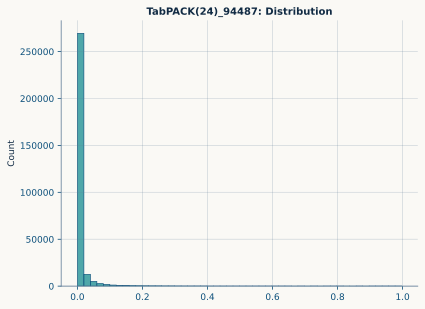

In [102]:
sns.histplot(test_preds, bins=50)
plt.title(f"{n}: Distribution")
plt.show()

In [ ]:
# # -- Full Data Train --

# _id = 'loc' if RUN_LOCAL else 'clt'
# model_name = f"{all_models[_id][0]}_({x_tr.shape[1]})"
# params = all_models[_id][1].copy()

# print(f"🚀 Training {model_name} on {get_system_info()}\n")
# print(f"train={X.shape}, test={X_test.shape}")

# all_cats = cat_cols + bool_cols
# cat_idx = [[*X.columns].index(f) for f in all_cats]
# print(f"cat_idx: {cat_idx}")

# model = TabPFNClassifier(**params, categorical_features_indices=cat_idx)
# model.fit(X, y)

# # - Predictions -
# if _id == 'loc':
#     batches = 10_000
#     # _oofs = []
#     # for batch in range(0, len(x_ts), batches):
#     #     chunk = x_ts.iloc[batch:batch + batches]
#     #     _oofs.append(model.predict_proba(chunk)[:, 1])
#     # val_preds = np.concatenate(_oofs)
#     # auc = np.round(roc_auc_score(y_ts, val_preds), 5)
#     # print(f"AUC: {auc}\n")

#     p0 = time() 
#     _preds = []
#     print(f"⧗ Predicting test({len(X_test)}) in batch({batches})... ", end="")
#     for batch in range(0, len(X_test), batches):
#         print(f"{batch}.. ", end="")
#         chunk = X_test.iloc[batch:batch + batches]
#         _preds.append(model.predict_proba(chunk)[:, 1])
#     p1 = time()
#     pp = (p1-p0) / 60
#     print(f"Done ⏰ {pp:.3f} mins")
#     test_preds = np.concatenate(_preds)
# else:
#     batches = 10_000
#     # _oofs = []
#     # for batch in range(0, len(x_ts), batches):
#     #     chunk = x_ts.iloc[batch:batch + batches]
#     #     _oofs.append(model.predict_proba(chunk)[:, 1])
#     # val_preds = np.concatenate(_oofs)
#     # auc = np.round(roc_auc_score(y_ts, val_preds), 5)
#     # print(f"AUC: {auc}\n")

#     p0 = time() 
#     _preds = []
#     print(f"⧗ Predicting test({len(X_test)}) in batch({batches})... ", end="")
#     for batch in range(0, len(X_test), batches):
#         print(f"{batch}.. ", end="")
#         chunk = X_test.iloc[batch:batch + batches]
#         _preds.append(model.predict_proba(chunk)[:, 1])
#     p1 = time()
#     pp = (p1-p0) / 60
#     print(f"\nDone ⏰ {pp:.3f} mins")
#     test_preds = np.concatenate(_preds)

# submit[TARGET] = test_preds
# submit.to_csv(f"submit_{model_name}.csv", index=False)

# submit

In [ ]:
# AUC: 0.94895
# print(auc)
# y_tr.values[105:115]

In [ ]:
# explainer_fsii = shapiq.Explainer(
#     model=model,
#     data=x_tr.to_numpy(),
#     labels=y_tr.values,
#     index="FSII",
#     max_order=2,
#     # empty_prediction=avg_pred,
# )
# fsii = explainer_fsii.explain(x_ts.to_numpy()[109], budget=50)
# print(fsii)

# fsii.plot_force(feature_names=x_ts.columns)

In [ ]:
# class CFG:
#     FOLDS = 5
#     SEED = 42
#     TE = True if 'nums_to_cats' in globals() else False
#     ES = 250
#     VERB = 300
#     PREDICT_TEST = False

# FOLDS = 3
# skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

# _id = 'loc' if RUN_LOCAL else 'clt'
# model_name = all_models[_id][0]
# print(f"🚀 Training {model_name} with {FOLDS} Folds\n")

# oof_preds  = np.zeros(len(X))
# test_preds = np.zeros(len(X_test))

# fold_scores = []
# best_iterations = []
# feat_importances = []

# all_cats = cat_cols + bool_cols

# t0 = time()

# for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
#     X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
#     y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
#     X_tst = X_test.copy() # .sample(n=50_000, random_state=42)

#     print("="*15)
#     print(f"### Fold {fold}/{FOLDS}")
#     print("="*15)

#     # Target encoding
#     if CFG.TE:
#         te_cols = nums_to_cats + INTER # + floor_cols
#         # te_cols = nums_to_cats + INTER # + floor_cols + digit_cols + bin_cols
#         smooth = 'auto'
#         print(f"⚡️ scikit_TE (smooth={smooth}) | features ({len(te_cols)})")
#         TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
#         tr_enc = TE.fit_transform(X_tr[te_cols], y_tr)
#         va_enc = TE.transform(X_val[te_cols])
#         ts_enc = TE.transform(X_tst[te_cols])

#         te_names = [f"TE{smooth}_{col}" for col in te_cols]
#         X_tr[te_names]  = tr_enc
#         X_val[te_names] = va_enc
#         X_tst[te_names] = ts_enc

#         combos_to_drop = te_cols

#         X_tr  = X_tr.drop(columns=combos_to_drop)
#         X_val = X_val.drop(columns=combos_to_drop)
#         X_tst = X_tst.drop(columns=combos_to_drop)
#     # ------------------------------------------------------------------------------
#     if fold == 1: print(f"train={X_tr.shape}, valid={X_val.shape}")

#     seeder = 42 # + (idx-1)
#     params = all_models[_id][1].copy()

#     cat_idx = [[*X_tr.columns].index(f) for f in all_cats]
#     print(f"cat_idx: {cat_idx}")

#     model = TabPFNClassifier(**params, categorical_features_indices=cat_idx)
#     model.fit(X_tr, y_tr)

#     # - oof/test predictions -
#     if 'loc' in model_name:
#         val_preds = model.predict_proba(X_val)[:, 1]
#         oof_preds[val_idx] = val_preds
#         # - Split test if local (200k limit)
#         batches = 150_000
#         if CFG.PREDICT_TEST: # ⚠️
#             p0 = time()
#             print(f"⧗ Predicting test({len(X_tst)}) in batch({batches })... ", end="")
#             part_1_preds = model.predict_proba(X_tst.iloc[:batches ])
#             part_2_preds = model.predict_proba(X_tst.iloc[batches :])
#             p1 = time()
#             pp = (p1 - p0) / 60
#             print(f"Done ⏰ {pp:.3f}mins")
#             test_preds += np.vstack((part_1_preds, part_2_preds))[:, 1]
#     else:
#         batches = 10_000
#         _oofs = []
#         for batch in range(0, len(X_val), batches):
#             chunk = X_val.iloc[batch : batch + batches]
#             _oofs.append(model.predict_proba(chunk)[:, 1])
#         val_preds = np.concatenate(_oofs)
#         oof_preds[val_idx] = val_preds

#         if CFG.PREDICT_TEST: # ⚠️
#             p0 = time() 
#             _preds = []
#             print(f"⧗ Predicting test({len(X_tst)}) in batch({batches})... ", end="")
#             for batch in range(0, len(X_tst), batches):
#                 chunk = X_tst.iloc[batch : batch + batches]
#                 _preds.append(model.predict_proba(chunk)[:, 1])
#             p1 = time()
#             pp = (p1 - p0) / 60
#             print(f"Done ⏰ {pp:.3f}mins")
#             test_preds += np.concatenate(_preds)

#     # feat_importances.append(np.asarray(model.feature_importances_))

#     fold_score = roc_auc_score(y_val, val_preds)
#     fold_scores.append(fold_score)

#     best_iter = model.n_classes_
#     best_iterations.append(best_iter)

#     print(f"{Fore.YELLOW}{Style.BRIGHT}Fold {fold} | AUC: {fold_score:.6f}{Style.RESET_ALL}", end=" | ")
#     print(f"seed={seeder}, tree={best_iter}\n")
#     torch.cuda.empty_cache()

# test_preds /= FOLDS

# model_name = model_name + f"({X_tr.shape[1]})"
# features_used = X_tr.columns

# ## -- CV results --
# fold_results = {}

# print(f"\n{'='*50}")
# print(f"{FOLDS}-FOLD CV: {model_name} | {X_tr.shape}")
# print(f"{'='*50}")
# for i, (s, t) in enumerate(zip(fold_scores, best_iterations), 1):
#     print(f" • Fold {i} AUC: {s:.6f} @ tree {t}")
#     fold_results[f'fold_{i}'] = s

# ## -- Final out-of-fold score --
# oof_auc = np.round(roc_auc_score(y, oof_preds), 6)
# avg_auc = np.round(np.mean(fold_scores), 6)
# std_auc = np.round(np.std(fold_scores), 6)

# print("-"*50)
# print(f"OOF score: {Fore.BLUE}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
# print(f"AVG score: {Fore.BLUE}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
# print("-"*50)

# t1 = time()
# tt = (t1 - t0) / 60
# print(f"{tt:.2f} mins\n")

# del X_tr, X_val, y_tr, y_val, model

In [ ]:
# ==================================================
# 3-FOLD CV: TABPFN2loc(24) | (200000, 24)
# ==================================================
#  • Fold 1 AUC: 0.946154 @ tree 2
#  • Fold 2 AUC: 0.949235 @ tree 2
#  • Fold 3 AUC: 0.947755 @ tree 2
# --------------------------------------------------
# OOF score: 0.947693
# AVG score: 0.947715 ± 0.001258
# --------------------------------------------------
# 9.89 mins

In [ ]:
# n = f"{model_name}_{str(avg_auc).split('.')[1]}"

# # fold_df = pd.DataFrame.from_dict(fold_results, orient='index', columns=['score'])
# # print(fold_df.to_string())

# print("-"*25)
# print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
# print("-"*25)

# print(f"{tt:.2f} mins")

In [ ]:
# submit[TARGET] = test_preds

# submit.to_csv(f"submit_{n}.csv", index=False)
# # np.save(f"oof_{n}.npy", oof_preds)
# # np.save(f"test_{n}.npy", test_preds)

# submit

In [ ]:
# ## -- Plot oof distributions --
# _, axs = plt.subplots(1, 3, figsize=(12, 3.5))

# CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
# axs[0].set_title(f"Calibration")

# RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
# axs[1].set_title(f"ROC-Curve")

# sns.histplot(oof_preds, ax=axs[2])
# axs[2].set_title(f"Distribution")

# # for ax in axs:
# #     ax.legend(loc='lower right')

# plt.tight_layout(pad=0.2)
# plt.show()

In [ ]:
# # Feature Importances --
# top_n = 30

# imp_df = pd.Series(np.mean(feat_importances, axis=0), index=features_used).sort_values()[-top_n:]
# print(f"Total used features: {len(features_used)}\n")

# ax = imp_df.plot.barh(figsize=(12.5, 8))
# ax.set_title(f"{n}: Avg. {FOLDS}-Fold importances", loc='left')
# ax.grid(True)

# plt.tight_layout()
# plt.show()

In [ ]:
# !rm -r /kaggle/working